# 02 · Preprocessing

Turns the raw rows into one clean row per song. Every step prints how many rows it removes,
so each decision from notebook 01 can be checked. The logic lives in `src/data/load.py`; this
notebook runs it step by step.

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src import config

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
FIG = config.FIGURES
FIG.mkdir(parents=True, exist_ok=True)
from src.data.load import load_raw, clean_catalog, song_key
raw = load_raw()
print(f"raw rows: {len(raw):,}")

raw rows: 114,000


## Step by step

In [2]:
steps = []
d = raw.dropna(subset=["track_name", "artists", "album_name"])
steps.append(("drop rows with missing text", len(d)))

genres = d.groupby("track_id")["track_genre"].agg(lambda s: sorted(set(s)))
d = d.sort_values("popularity", ascending=False).drop_duplicates("track_id").assign(genres=lambda x: x.track_id.map(genres))
steps.append(("one row per track id (genres merged into a list)", len(d)))

d["song_key"] = song_key(d.track_name, d.artists)
steps.append(("one row per song (title + main artist)", d.song_key.nunique()))
d = d.drop_duplicates("song_key")
d = d[(d.tempo > 0) & (d.time_signature > 0) & (d.duration_ms > 30_000)]
steps.append(("drop failed audio analyses and clips under 30 s", len(d)))
pd.DataFrame(steps, columns=["step", "rows left"]).set_index("step")

,rows left
step,
drop rows with missing text,113999
one row per track id (genres merged into a list),89740
one row per song (title + main artist),78249
drop failed audio analyses and clips under 30 s,78097


The song-key rule (`song_key` in `src/data/load.py`) strips anything after ` - `, `(` or `[`, so
*Bohemian Rhapsody - Remastered 2011* and *Bohemian Rhapsody* collapse into one song. Remixes are
kept apart because a remix is a different recording. Examples of groups that were merged (the
most popular copy is kept, and the genre lists are combined):

In [3]:
dup = (raw.drop_duplicates("track_id")
          .assign(key=lambda x: song_key(x.track_name, x.artists)))
groups = dup[dup.duplicated("key", keep=False)].sort_values(["key", "popularity"], ascending=[True, False])
groups[groups.key.isin(groups.key.drop_duplicates().sample(4, random_state=3))][["track_name", "artists", "album_name", "popularity", "track_genre"]]

,track_name,artists,album_name,popularity,track_genre
46168,Around The World,The Nightraver;DJ Trevor,Around The World,24,happy
46717,Around The World - Radio Version,The Nightraver;DJ Trevor,Around The World,17,happy
46960,Around The World,The Nightraver;DJ Trevor,Happy Hardcore Top 100,15,happy
54379,Aurora - Mixed,alva noto;Ryuichi Sakamoto,DJ-Kicks (DJ Tennis) [DJ Mix],13,idm
54430,Aurora,alva noto;Ryuichi Sakamoto,Insen (Remaster),13,idm
74417,Futuros Amantes,Chico Buarque,Paratodos,43,mpb
74452,Futuros Amantes,Chico Buarque,Chico Buarque Essencial (Box),42,mpb
107169,Heaven Is a Place On Earth,Belinda Carlisle,Greatest Vol.1 - Belinda Carlisle,69,synth-pop
107124,Heaven Is a Place On Earth,Belinda Carlisle,Heaven on Earth (30th Anniversary Edition),50,synth-pop


## Capping tracks per genre

The full clean catalog has about 78,000 songs. Evaluating the models scores every song for every
playlist, so the catalog is capped to the 200 most popular songs of each genre (about 22,800 songs).
This is a sampling choice for speed, not a quality filter: set `TRACKS_PER_GENRE_CAP = None` in
`src/config.py` to use everything.

In [4]:
tracks = clean_catalog(raw)
print(f"catalog: {len(tracks):,} songs, {tracks.genres.explode().nunique()} genres, "
      f"{tracks.main_artist.nunique():,} main artists")
print("genres per song:", tracks.genres.str.len().value_counts().sort_index().to_dict())
tracks.head()

catalog: 22,800 songs, 114 genres, 7,806 main artists
genres per song: {1: 16208, 2: 4589, 3: 1266, 4: 535, 5: 145, 6: 40, 7: 15, 8: 1, 9: 1}


,track_id,track_uri,track_name,artists,artist_list,main_artist,album_name,popularity,duration_ms,explicit,key,mode,key_name,time_signature,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,primary_genre,genres
0,3nqQXoyQOWXiESFLlDF1hG,spotify:track:3nqQXoyQOWXiESFLlDF1hG,Unholy (feat. Kim Petras),Sam Smith;Kim Petras,"[Sam Smith, Kim Petras]",Sam Smith,Unholy (feat. Kim Petras),100,156943,False,2,1,D major,4,0.714,0.472,-7.375,0.0864,0.01300,0.000005,0.2660,0.238,131.121,dance,"[dance, pop]"
1,2tTmW7RDtMQtBk7m2rYeSw,spotify:track:2tTmW7RDtMQtBk7m2rYeSw,"Quevedo: Bzrp Music Sessions, Vol. 52",Bizarrap;Quevedo,"[Bizarrap, Quevedo]",Bizarrap,"Quevedo: Bzrp Music Sessions, Vol. 52",99,198937,False,2,1,D major,4,0.621,0.782,-5.548,0.0440,0.01250,0.033000,0.2300,0.550,128.033,hip-hop,[hip-hop]
2,5ww2BF9slyYgNOk37BlC4u,spotify:track:5ww2BF9slyYgNOk37BlC4u,La Bachata,Manuel Turizo,[Manuel Turizo],Manuel Turizo,La Bachata,98,162637,False,7,0,G minor,4,0.835,0.679,-5.329,0.0364,0.58300,0.000002,0.2180,0.850,124.980,reggae,"[latin, latino, reggae, reggaeton]"
3,4uUG5RXrOk84mYEfFvj3cK,spotify:track:4uUG5RXrOk84mYEfFvj3cK,I'm Good (Blue),David Guetta;Bebe Rexha,"[David Guetta, Bebe Rexha]",David Guetta,I'm Good (Blue),98,175238,True,7,0,G minor,4,0.561,0.965,-3.673,0.0343,0.00383,0.000007,0.3710,0.304,128.040,pop,"[dance, edm, pop]"
4,6Sq7ltF9Qa7SNFBsV5Cogx,spotify:track:6Sq7ltF9Qa7SNFBsV5Cogx,Me Porto Bonito,Bad Bunny;Chencho Corleone,"[Bad Bunny, Chencho Corleone]",Bad Bunny,Un Verano Sin Ti,97,178567,True,1,0,C# minor,4,0.911,0.712,-5.105,0.0817,0.09010,0.000027,0.0933,0.425,92.005,latin,"[latin, latino, reggae, reggaeton]"


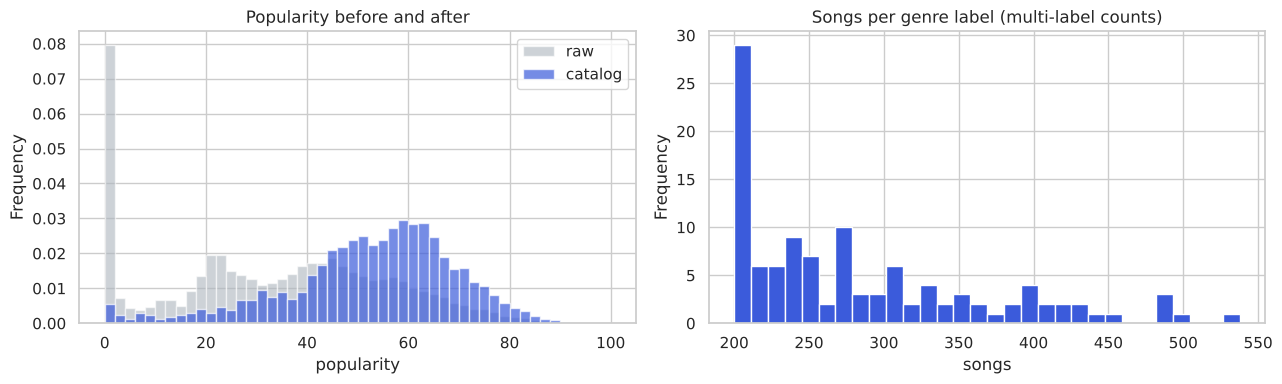

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
raw.popularity.plot.hist(bins=50, ax=axes[0], alpha=.6, density=True, label="raw", color="#adb5bd")
tracks.popularity.plot.hist(bins=50, ax=axes[0], alpha=.7, density=True, label="catalog", color="#3b5bdb")
axes[0].legend(); axes[0].set(title="Popularity before and after", xlabel="popularity")
tracks.genres.explode().value_counts().plot.hist(bins=30, ax=axes[1], color="#3b5bdb")
axes[1].set(title="Songs per genre label (multi-label counts)", xlabel="songs")
plt.tight_layout(); plt.savefig(FIG / "02_catalog.png"); plt.show()

The sample leans toward popular songs (by design) but every genre keeps a full set, and multi-label genres push some genres above 200.

In [6]:
config.DATA_PROCESSED.mkdir(parents=True, exist_ok=True)
tracks.to_parquet(config.TRACKS_CLEAN)
print("saved", config.TRACKS_CLEAN.relative_to(config.PROJECT_ROOT), tracks.shape)

saved data/processed/tracks_clean.parquet (22800, 25)
